# P1.4 — Contrast and Image Quality: T1, T2, PD, SNR, resolution and scan time

**Part:** Pass 1 — The big picture (notebook 4 of 5) · **Reading time:** ~40 min · **Previous:** [P1.3 From Signal to Image](P1.3_From_Signal_to_Image.ipynb) · **Next:** [P1.5 Speed, Artifacts and Safety](P1.5_Speed_Artifacts_and_Safety.ipynb) · **Refreshers you may want:** [ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb), [2D Fourier & images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

**Why this notebook matters.** Unlike a CT or X-ray image, an MRI image has no single "correct" brightness: the same
brain can make cerebrospinal fluid black or white, depending on two timing parameters, $TE$ and $TR$. This flexibility
is MRI's superpower in diagnosis. The second half of the notebook is about the price we pay for every image: the
**signal-to-noise ratio** (SNR), **resolution** and **scan time** are locked in a triangle of trade-offs — understanding
it is the key to designing (or just choosing) good protocols.

## Learning goals

1. Explain what makes tissues differ in $T_1$, $T_2$ and proton density (PD), with typical values.
2. Explain how $TE$ controls $T_2$ weighting and $TR$ controls $T_1$ weighting; choose $TE/TR$ for **T1-, T2- and PD-weighted** images.
3. Know the main "extra" contrasts: $T_2^*$, inversion recovery (FLAIR/STIR), flip angle in gradient echo, contrast agents, diffusion, flow, BOLD.
4. State the SNR equation $SNR \propto f_{seq}\cdot\text{voxel volume}\cdot\sqrt{T_{meas}}$ and use it to predict the effect of protocol changes.
5. Explain the **SNR–resolution–time triangle** and the effect of field strength.

## Symbols used in this notebook

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $M_0$ | equilibrium magnetization ∝ proton density ("PD") | normalized | 0.7–1 for soft tissue |
| $T_1$, $T_2$, $T_2^*$ | longitudinal, transverse, effective-transverse relaxation **time constants** | s | see table |
| $R_1 = 1/T_1$ | longitudinal relaxation **rate** | s⁻¹ | |
| $TE$ | echo time (excitation → center of k-space) | s | 2–120 ms |
| $TR$ | repetition time (between excitations) | s | 3 ms – 10 s |
| $TI$ | inversion time (inversion pulse → excitation) | s | 0.1–2.5 s |
| $\theta$ | flip angle | rad / ° | |
| $\theta_E$ | Ernst angle: flip angle giving maximum spoiled-GRE signal | rad / ° | |
| $S$ | image signal (intensity) of a tissue | a.u. | |
| $f_{seq}$ | sequence-dependent signal factor (relaxation weighting, flip angle) | – | |
| $C$ | contrast between two tissues, $S_A - S_B$ | a.u. | |
| $SNR$ | signal-to-noise ratio: mean signal ÷ noise standard deviation | – | 10–100 |
| $\sigma_n$ | noise standard deviation | a.u. | |
| $\delta_x,\delta_y,\delta_z$ | voxel dimensions (pixel size in-plane, slice thickness) | m | 0.5–5 mm |
| $T_{meas}$ | total time the ADC is sampling for an image | s | |
| $T_{read}$ | duration of one readout | s | 1–10 ms |
| $N_{TR}$ | number of TR periods (excitations) | – | |
| $NEX$ | number of averages | – | 1–4 |
| $N_{PE}$, $N_{read}$ | # phase-encode lines, # readout samples | – | 128–512 |
| $BW_{read}$ | receiver bandwidth | Hz | 30–250 kHz |
| $T_{scan}$ | scan time $= TR\cdot N_{TR}$ (incl. averages) | s | |
| $R$, $g$ | parallel-imaging acceleration factor; g-factor (≥ 1) | – | $R$ 2–4 |
| $B_0$ | main field | T | 1.5 T, 3 T |
| $r_1$ | relaxivity of a contrast agent | s⁻¹ mM⁻¹ | ~3–5 for Gd agents |
| $c_{Gd}$ | contrast-agent concentration | mM (mmol/L) | 0.1–1 mM in tissue |

**Symbol clash:** here $C$ is contrast (in other notebooks also coil sensitivity or capacitance) and $R$ the acceleration
factor (also resistance). $T_1, T_2$ are times, $R_1, R_2$ the corresponding rates.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. One body, many contrasts

![MRI contrasts](../images/3DMagic.gif)

*The same anatomy with different contrasts (from Larson's book).*

![Brain contrasts](../images/contrast_brain_example.png)

*T1-weighted, T2-weighted and other contrasts of the brain. In a T1-weighted image CSF (the fluid in the ventricles)
is dark and white matter is brighter than gray matter; in a T2-weighted image CSF is bright.*

The image intensity of a tissue depends on three tissue properties — proton density ($M_0$), $T_1$ and $T_2$ (or
$T_2^*$) — and on sequence parameters we choose ($TE$, $TR$, flip angle, preparation pulses). Each image is "weighted"
towards one property by the choice of parameters.

## 2. Why tissues have different $T_1$ and $T_2$

Relaxation is caused by **fluctuating magnetic fields** that each proton feels from its neighbours as molecules tumble
and move.

* **$T_1$** (giving energy back to the surroundings) is efficient only when the fluctuations contain frequencies near
  the Larmor frequency. Small free water molecules tumble far too fast (→ long $T_1$, e.g. CSF ~4 s); fat molecules are
  big and tumble at "just the right" rate (→ short $T_1$, ~0.3–0.4 s). Because $f_0$ grows with $B_0$, **$T_1$ gets
  longer at higher field**.
* **$T_2$** (loss of phase coherence) is also caused by slow fluctuations and static local differences. Free fluids
  have long $T_2$ (CSF ~2 s); solids and tightly bound water (tendon, cortical bone) have $T_2$ of < 1 ms and appear black
  in conventional MRI; most soft tissues are in between (40–100 ms). $T_2$ depends only weakly on $B_0$.
* **Proton density** ($M_0$) varies less (most soft tissues 70–90 % of pure water).

Approximate values at 3 T (literature values scatter by ±20–30 % between methods and studies):

| Tissue | $T_1$ [ms] | $T_2$ [ms] |
|---|---|---|
| White matter | 800–1100 | 60–80 |
| Gray matter | 1300–1800 | 80–100 |
| CSF | ~4000 | ~1500–2000 |
| Muscle | ~1400 | ~35–50 |
| Fat | ~370–400 | ~70–130 |
| Liver | ~800 | ~35 |
| Arterial blood | ~1700 | ~150 (oxygenated) |

> **⚠️ Common confusion:** the original book's 3 T table lists white matter $T_2$ = 110 ms > gray matter $T_2$ = 80 ms;
> most studies find the opposite (gray matter $T_2$ slightly *longer* than white matter). The order matters for T2-weighted
> contrast: gray matter appears slightly brighter than white matter on T2-weighted images.

For the simulations below we use the tissue phantom `mt.tissue_phantom`, which has textbook-like values at ~1.5 T:

fat          : M0 = 0.90, T1 =   260 ms, T2 =    80 ms
white matter : M0 = 0.70, T1 =   600 ms, T2 =    80 ms
gray matter  : M0 = 0.80, T1 =   950 ms, T2 =   100 ms
CSF          : M0 = 1.00, T1 =  4000 ms, T2 =  2000 ms
lesion       : M0 = 0.85, T1 =  1300 ms, T2 =   150 ms


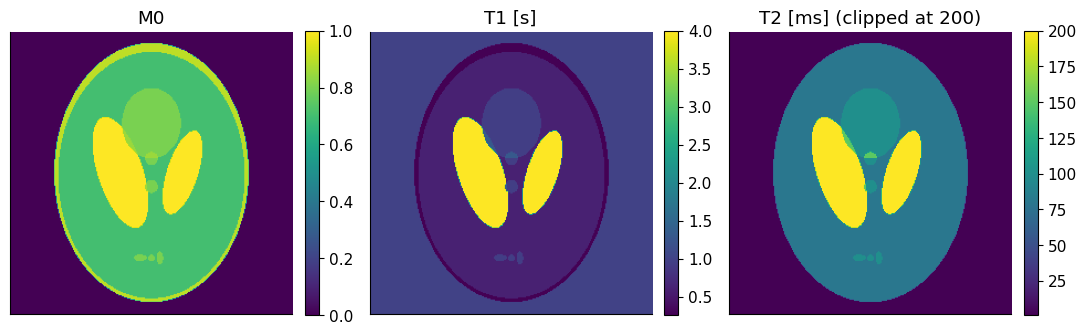

In [2]:
ph = mt.tissue_phantom(256)
names = {1: "fat", 2: "white matter", 3: "gray matter", 4: "CSF", 5: "lesion"}
tissues = {}
for lab, name in names.items():
    sel = ph["labels"] == lab
    tissues[name] = (ph["M0"][sel][0], ph["T1"][sel][0], ph["T2"][sel][0])
    print(f"{name:13s}: M0 = {tissues[name][0]:.2f}, T1 = {tissues[name][1]*1e3:5.0f} ms, T2 = {tissues[name][2]*1e3:5.0f} ms")
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
for a, key, unit, sc in zip(ax, ["M0", "T1", "T2"], ["", " [s]", " [ms]"], [1, 1, 1e3]):
    mt.show_image(ph[key]*sc if key != "T2" else np.minimum(ph[key]*sc, 200), ax=a, title=key + unit + (" (clipped at 200)" if key == "T2" else ""), colorbar=True, cmap="viridis")
plt.tight_layout(); plt.show()

*Interpretation:* these three maps are what the body "is" for MRI. An image is a mixture of them, mixed by the
sequence parameters.

➡️ **Go deeper:** [D1 Basic Contrast Mechanisms](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb) · [A3 In Vivo Spin Physics](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb)

## 3. $TE$ controls $T_2$ weighting, $TR$ controls $T_1$ weighting

For a **spin echo** with a 90° excitation (and $TE \ll TR$) the signal is

$$S = M_0\,\bigl(1 - e^{-TR/T_1}\bigr)\,e^{-TE/T_2}.$$

*In words:* three factors multiply. $M_0$ is how much magnetization the tissue has; $(1-e^{-TR/T_1})$ is how much of it
has **recovered** along $z$ since the last excitation $TR$ seconds ago ($T_1$ recovery, P1.1); $e^{-TE/T_2}$ is how much
of the tipped magnetization **survives** until the echo is measured at $TE$ ($T_2$ decay). For a gradient echo replace
$T_2$ by $T_2^*$. Implemented as `mt.spin_echo_signal(TE, TR, T1, T2, M0)` (times in seconds).

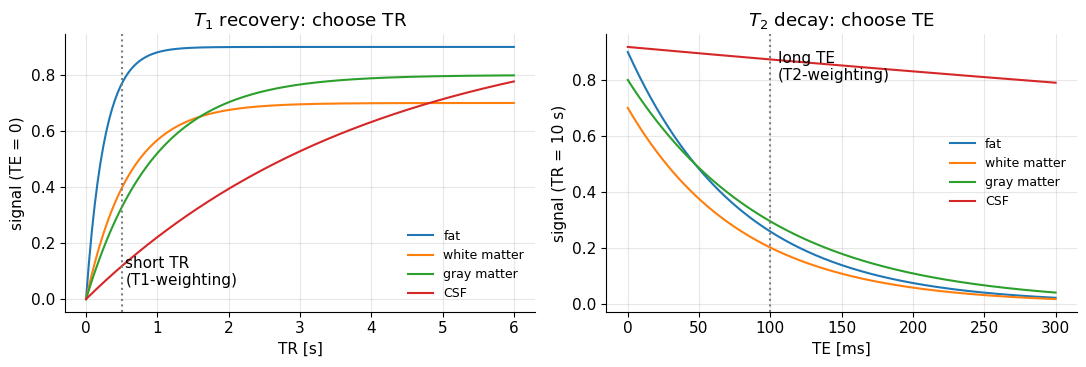

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
TE = np.linspace(0, 0.3, 300); TR = np.linspace(0, 6, 300)
for name, (M0, T1, T2) in tissues.items():
    if name == "lesion": continue
    ax[0].plot(TR, mt.spin_echo_signal(0.0, TR, T1, T2, M0), label=name)
    ax[1].plot(TE*1e3, mt.spin_echo_signal(TE, 10.0, T1, T2, M0), label=name)
ax[0].axvline(0.5, color="gray", ls=":"); ax[0].text(0.55, 0.05, "short TR\n(T1-weighting)")
ax[0].set(xlabel="TR [s]", ylabel="signal (TE = 0)", title="$T_1$ recovery: choose TR")
ax[1].axvline(100, color="gray", ls=":"); ax[1].text(105, 0.8, "long TE\n(T2-weighting)")
ax[1].set(xlabel="TE [ms]", ylabel="signal (TR = 10 s)", title="$T_2$ decay: choose TE")
for a in ax: a.legend(fontsize=9)
plt.tight_layout(); plt.show()

*Interpretation:*

* **Left (TR):** at short TR (~0.5 s) fat and white matter have recovered much more than CSF → large differences due
  to $T_1$. At very long TR all tissues have fully recovered and only $M_0$ differs.
* **Right (TE):** at very short TE nothing has decayed yet (only $M_0$ differs); at long TE (~100 ms) CSF ($T_2$ = 2 s)
  is still bright while tissues with $T_2$ ≈ 80 ms have lost most of their signal → $T_2$ contrast.

This gives the three classic recipes:

| Weighting | TR | TE | Bright | Dark |
|---|---|---|---|---|
| **T1-weighted** | short (≈ $T_1$, 400–700 ms) | short (< 20 ms) | short $T_1$: fat, white matter, Gd-enhanced tissue | long $T_1$: CSF, edema |
| **T2-weighted** | long (≥ 3 $T_1$, 3–6 s) | long (≈ $T_2$, 80–120 ms) | long $T_2$: CSF, edema, many lesions | short $T_2$ |
| **PD-weighted** | long (3–6 s) | short (< 20 ms) | high proton density | low proton density |

(A short-TR **and** long-TE scan mixes both effects, which partly cancel — rarely useful.)

Let's make the three images from the phantom maps:

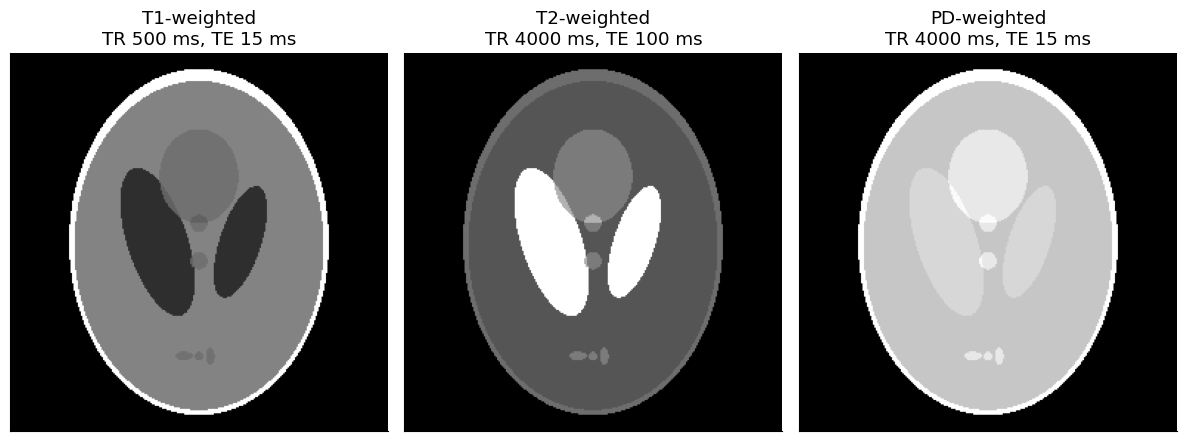

In [4]:
protocols = {"T1-weighted\nTR 500 ms, TE 15 ms": (0.015, 0.5),
             "T2-weighted\nTR 4000 ms, TE 100 ms": (0.100, 4.0),
             "PD-weighted\nTR 4000 ms, TE 15 ms": (0.015, 4.0)}
fig, ax = plt.subplots(1, 3, figsize=(12, 4.3))
for a, (title, (TE_, TR_)) in zip(ax, protocols.items()):
    S = mt.spin_echo_signal(TE_, TR_, ph["T1"], ph["T2"], ph["M0"])
    mt.show_image(S, ax=a, title=title)
plt.tight_layout(); plt.show()

*Interpretation:* same "patient", three looks. T1w: CSF in the ventricles is black, fat ring bright, white matter
brighter than gray matter. T2w: CSF very bright, the small "lesions" (longer $T_2$) stand out. PDw: everything is
fairly bright and similar — mainly proton density differences.

How strong the contrast is between two tissues depends on both TE and TR. Here is the white matter–CSF contrast
$C = S_{WM} - S_{CSF}$ for all combinations:

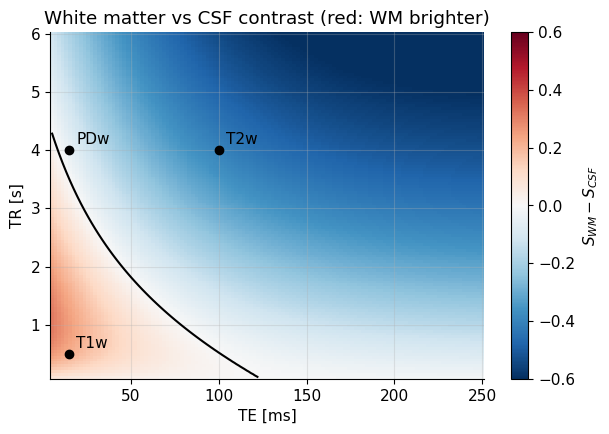

In [5]:
TEg, TRg = np.meshgrid(np.linspace(0.005, 0.25, 120), np.linspace(0.1, 6, 120))
M0w, T1w, T2w = tissues["white matter"]; M0c, T1c, T2c = tissues["CSF"]
C = mt.spin_echo_signal(TEg, TRg, T1w, T2w, M0w) - mt.spin_echo_signal(TEg, TRg, T1c, T2c, M0c)
plt.figure(figsize=(7, 4.5))
im = plt.pcolormesh(TEg*1e3, TRg, C, cmap="RdBu_r", vmin=-0.6, vmax=0.6, shading="auto")
plt.colorbar(im, label="$S_{WM} - S_{CSF}$")
plt.contour(TEg*1e3, TRg, C, levels=[0], colors="k")
for name, (TE_, TR_) in zip(["T1w", "T2w", "PDw"], protocols.values()):
    plt.plot(TE_*1e3, TR_, "ko"); plt.text(TE_*1e3 + 4, TR_ + 0.1, name)
plt.xlabel("TE [ms]"); plt.ylabel("TR [s]"); plt.title("White matter vs CSF contrast (red: WM brighter)"); plt.show()

*Interpretation:* red = white matter brighter (T1-like), blue = CSF brighter (T2-like). The black line is where the two
tissues have *identical* signal — a poorly chosen protocol could make the ventricles invisible!

### Try it yourself (optional, interactive)

In [6]:
try:
    from ipywidgets import interact, FloatLogSlider, FloatSlider
    def explore(TE_ms=15, TR_ms=500):
        S = mt.spin_echo_signal(TE_ms*1e-3, TR_ms*1e-3, ph["T1"], ph["T2"], ph["M0"])
        plt.figure(figsize=(4.5, 4.5)); mt.show_image(S, title=f"TE {TE_ms:.0f} ms, TR {TR_ms:.0f} ms"); plt.show()
    interact(explore, TE_ms=FloatSlider(min=5, max=250, step=5, value=15),
             TR_ms=FloatLogSlider(base=10, min=2, max=4, step=0.05, value=500))
except ImportError:
    print("ipywidgets not available - skip this cell")

interactive(children=(FloatSlider(value=15.0, description='TE_ms', max=250.0, min=5.0, step=5.0), FloatLogSlid…

➡️ **Go deeper:** [D1 Basic Contrast Mechanisms](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb) · [D3 Gradient and Spin Echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb) · [D4 Image Contrast Examples](../pass2_deep_dive/D4_Image_Contrast_Examples.ipynb) · [C2 MRI Signal Equation](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb)

## 4. More contrast knobs

### 4.1 Flip angle in fast gradient-echo imaging

With very short TR (a few ms) a 90° pulse would leave almost no time for recovery. **Spoiled gradient-echo** sequences
(FLASH/SPGR) therefore use small flip angles. The steady-state signal is

$$S = M_0\,\sin\theta\,\frac{1-e^{-TR/T_1}}{1-\cos\theta\,e^{-TR/T_1}}\,e^{-TE/T_2^*},$$

*In words:* a bigger flip angle tips more magnetization into the transverse plane ($\sin\theta$) but leaves less along
$z$ for the next TR; the fraction balances recovery against consumption. The optimum is the **Ernst angle**
$\theta_E = \arccos(e^{-TR/T_1})$. ($\theta$ flip angle, $T_2^*$ effective transverse decay time; `mt.spoiled_gre_signal`,
`mt.ernst_angle`.)

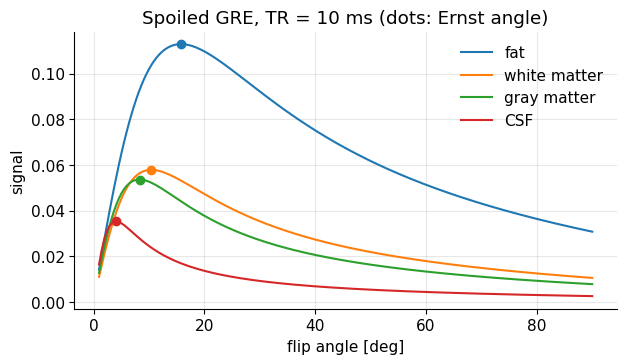

In [7]:
flip = np.deg2rad(np.linspace(1, 90, 200))
TR_g, TE_g = 0.010, 0.004                            # 10 ms TR, 4 ms TE
plt.figure(figsize=(7, 3.6))
for name in ["fat", "white matter", "gray matter", "CSF"]:
    M0, T1, T2 = tissues[name]
    S = mt.spoiled_gre_signal(flip, TE_g, TR_g, T1, T2*0.5, M0)    # assume T2* ~ T2/2 for illustration
    l, = plt.plot(np.degrees(flip), S, label=name)
    thE = mt.ernst_angle(TR_g, T1)
    plt.plot(np.degrees(thE), mt.spoiled_gre_signal(thE, TE_g, TR_g, T1, T2*0.5, M0), "o", color=l.get_color())
plt.xlabel("flip angle [deg]"); plt.ylabel("signal"); plt.legend(); plt.title("Spoiled GRE, TR = 10 ms (dots: Ernst angle)"); plt.show()

*Interpretation:* at small flip angles (~2–5°) the signal follows $M_0$ (PD-like); at larger angles short-$T_1$ tissue
(fat, white matter) stays bright while CSF saturates (T1-weighting). Fast 3D T1-weighted scans work like this.

### 4.2 Inversion recovery: nulling a tissue

A 180° **inversion pulse** flips $M_z$ to $-M_0$; we wait an **inversion time** $TI$ before exciting. During $TI$ each
tissue recovers through zero at its own time, $TI_{null} = T_1\ln 2$ (for long TR). Exciting exactly then makes that
tissue black: **FLAIR** nulls CSF (TI ≈ 2.5 s at 3 T), **STIR** nulls fat (TI ≈ 150–250 ms).

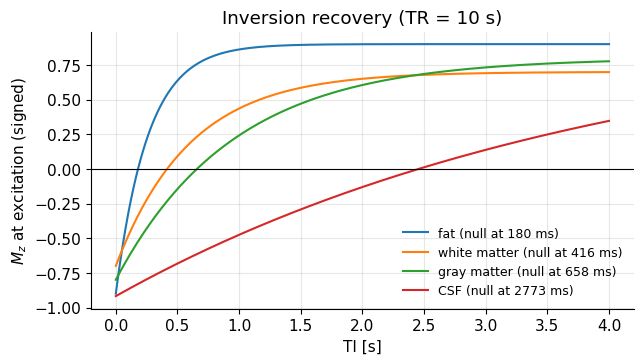

In [8]:
TI = np.linspace(0, 4, 400)
plt.figure(figsize=(7, 3.6))
for name in ["fat", "white matter", "gray matter", "CSF"]:
    M0, T1, T2 = tissues[name]
    plt.plot(TI, mt.inversion_recovery_signal(TI, 10.0, 0.0, T1, T2, M0), label=f"{name} (null at {T1*np.log(2)*1e3:.0f} ms)")
plt.axhline(0, color="k", lw=0.8)
plt.xlabel("TI [s]"); plt.ylabel("$M_z$ at excitation (signed)"); plt.legend(fontsize=9); plt.title("Inversion recovery (TR = 10 s)"); plt.show()

*Interpretation:* each curve crosses zero at its own $TI$. Most scanners show the *magnitude*, so a tissue crossing
zero becomes black.

### 4.3 The wider palette

| Contrast | What it shows | Used for |
|---|---|---|
| $T_2^*$ / susceptibility (gradient echo, SWI) | iron, blood products, deoxyhemoglobin, calcium | micro-bleeds, venography |
| **Contrast agents** (gadolinium chelates) | Gd shortens $T_1$: $1/T_1 = 1/T_{1,0} + r_1 c_{Gd}$ | tumours, inflammation, blood-brain-barrier breakdown, angiography |
| **Diffusion** (DWI) | random motion of water molecules | stroke within minutes, tumour cellularity, fibre tracking |
| **Flow** (time-of-flight, phase contrast) | moving blood | angiography, flow quantification |
| **BOLD** ($T_2^*$ change with blood oxygenation) | brain activity | functional MRI (fMRI) |
| **Fat/water** (chemical shift) | fat vs. water content | fat suppression, liver fat quantification |
| Quantitative mapping | $T_1$, $T_2$, $T_2^*$ in ms | tissue characterization, MR fingerprinting |

In [9]:
# How much does a gadolinium agent brighten a T1-weighted image?  1/T1 = 1/T1_0 + r1 * c
r1 = 4.0                                    # relaxivity [1/(s mM)], typical for Gd chelates at 1.5-3 T
c = np.array([0, 0.1, 0.25, 0.5, 1.0])      # concentration in tissue [mM]
T1_0, T2_0 = 1.3, 0.15                      # a lesion-like tissue [s]
T1_c = 1/(1/T1_0 + r1*c)
S = mt.spin_echo_signal(0.015, 0.5, T1_c, T2_0)
for ci, t1, si in zip(c, T1_c, S):
    print(f"c = {ci:4.2f} mM: T1 = {t1*1e3:5.0f} ms, T1w signal = {si:.2f} ({si/S[0]:.1f}x)")

c = 0.00 mM: T1 =  1300 ms, T1w signal = 0.29 (1.0x)
c = 0.10 mM: T1 =   855 ms, T1w signal = 0.40 (1.4x)
c = 0.25 mM: T1 =   565 ms, T1w signal = 0.53 (1.8x)
c = 0.50 mM: T1 =   361 ms, T1w signal = 0.68 (2.3x)
c = 1.00 mM: T1 =   210 ms, T1w signal = 0.82 (2.8x)


*Interpretation:* a fraction of a millimolar of gadolinium makes tissue 2–4× brighter on a T1-weighted image —
that is why "enhancement after contrast" is so visible. (Safety aspects of gadolinium: P1.5.)

➡️ **Go deeper:** [D2 In Vivo Contrast Mechanisms](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) · [D3 Gradient and Spin Echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb) · [H2 Fast Imaging Pulse Sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb) · [J2 Spectral-Spatial RF Pulses](../pass2_deep_dive/J2_Spectral-Spatial_RF_Pulses.ipynb) (fat suppression)

## 5. Image quality: signal-to-noise ratio (SNR)

Every MRI image contains random **noise**, mostly thermal noise from the patient's body picked up by the receive coils
(P1.2). It is Gaussian, zero-mean, and independent in each k-space sample. The quality measure is the
**signal-to-noise ratio** $SNR = S/\sigma_n$ (mean signal of a tissue ÷ noise standard deviation $\sigma_n$).

The whole of MRI SNR is summarized in one proportionality:

$$SNR \;\propto\; f_{seq}\;\cdot\;\underbrace{\delta_x\,\delta_y\,\delta_z}_{\text{voxel volume}}\;\cdot\;\sqrt{T_{meas}} .$$

*In words:* SNR grows (1) with the signal produced by the sequence and tissue ($f_{seq}$, e.g. the spin-echo factor
above), (2) **linearly** with the voxel volume (more spins per voxel), and (3) with the **square root** of the total
time the ADC spends sampling, $T_{meas} = N_{TR}\cdot T_{read}$. The square root is the classic averaging law: signal
adds up linearly, independent noise only as $\sqrt{\ }$. System factors (field strength, coil) multiply this further.

Averaging demonstration: we add noise to the T1-weighted phantom image and average $NEX$ repetitions.

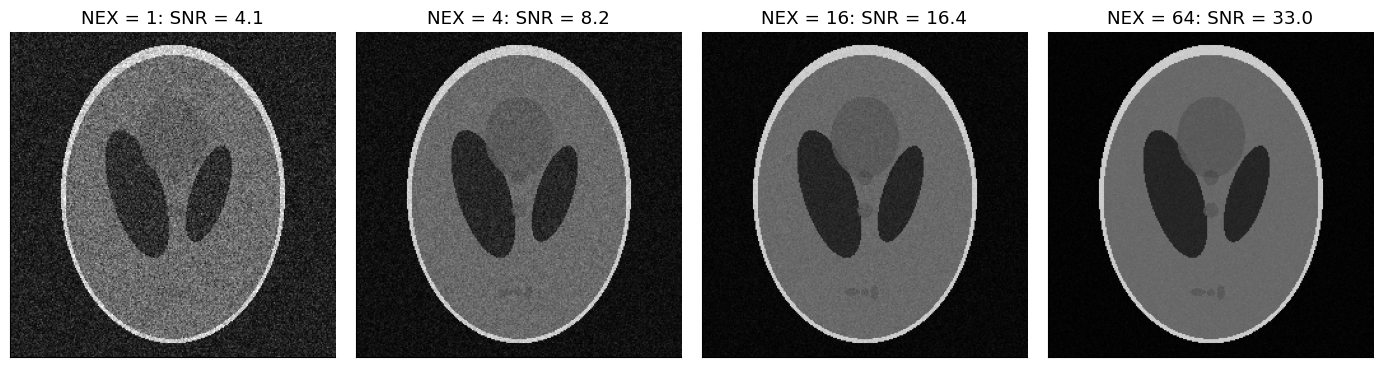

In [10]:
S_T1w = mt.spin_echo_signal(0.015, 0.5, ph["T1"], ph["T2"], ph["M0"])
wm = ph["labels"] == 2                                     # white-matter region for measuring SNR
sigma = 0.08                                               # noise std per acquisition (real and imaginary parts)
rng = np.random.default_rng(0)

fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
for a, NEX in zip(ax, [1, 4, 16, 64]):
    avg = np.mean([mt.add_complex_noise(S_T1w, sigma, rng) for _ in range(NEX)], axis=0)
    snr = S_T1w[wm].mean() / (avg - S_T1w)[wm].real.std()
    mt.show_image(np.abs(avg), ax=a, vmin=0, vmax=0.8, title=f"NEX = {NEX}: SNR = {snr:.1f}")
plt.tight_layout(); plt.show()

*Interpretation:* every 4× more averaging doubles the SNR ($\sqrt{4}=2$): 4×, 16×, 64× the time buys only 2×, 4×, 8×
better SNR. Averaging is the most expensive way to buy SNR. (We measure noise from the real part of the error; on
magnitude images the noise statistics change at low SNR — the background is not zero-mean, see G2.)

## 6. The SNR – resolution – scan-time triangle

> **🧭 Intuition:** pixels are buckets that collect signal. Smaller buckets (higher resolution) collect fewer spins, so
> each holds less signal against the same noise. To get it back you must listen longer. You can have any **two** of
> *high resolution*, *high SNR* and *short scan time* — but not all three.

Let's verify the SNR equation with a simulation in k-space. Noise of the same standard deviation is added to every
acquired k-space sample (as in a real scanner). We compare:

* **A** 256 × 256 matrix (reference),
* **B** only the central 128 × 128 (same FOV, pixels 2× larger in each direction, half the phase-encode lines, readouts
  half as long),
* **C** 256 × 256 with NEX = 4.

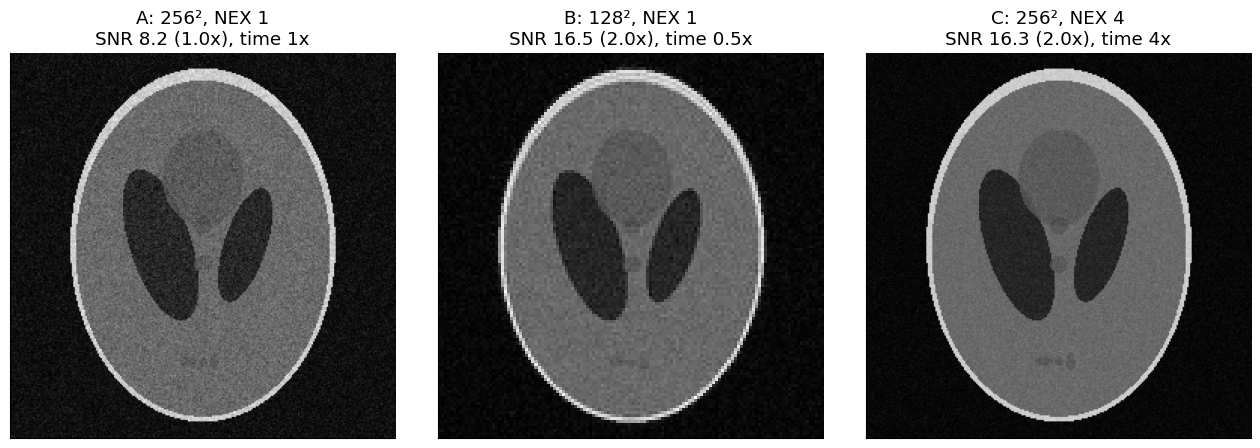

In [11]:
K_true = mt.fft2c(S_T1w)
N = 256
sig_k = 0.04                                                    # noise std per k-space sample (real & imag)
def recon(K_acq, n):
    """Reconstruct central n x n k-space on an n x n grid; rescale so tissue values are comparable."""
    c = N//2
    Kc = K_acq[c - n//2:c + n//2, c - n//2:c + n//2]
    return mt.ifft2c(Kc) * n / N                                # ortho FFT -> scale pixel values back to object units

def snr_of(img, n):
    ref = recon(K_true, n)                                      # noise-free version at the same resolution
    labels_n = ph["labels"][::N//n, ::N//n] if n < N else ph["labels"]
    sel = labels_n == 2
    return ref[sel].real.mean() / (img - ref)[sel].real.std()

A = recon(mt.add_complex_noise(K_true, sig_k, rng), 256)
B = recon(mt.add_complex_noise(K_true, sig_k, rng), 128)
C = np.mean([recon(mt.add_complex_noise(K_true, sig_k, rng), 256) for _ in range(4)], axis=0)
rows = [("A: 256², NEX 1", A, 256, 1.0), ("B: 128², NEX 1", B, 128, 0.5), ("C: 256², NEX 4", C, 256, 4.0)]
snrA = snr_of(A, 256)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
for a, (lab, img, n, time) in zip(ax, rows):
    s = snr_of(img, n)
    mt.show_image(np.abs(img), ax=a, vmin=0, vmax=0.8, title=f"{lab}\nSNR {s:.1f} ({s/snrA:.1f}x), time {time:g}x")
plt.tight_layout(); plt.show()

*Interpretation:* **B** has 4× the voxel volume but only 1/4 of the sampling time ($\tfrac12$ the lines × $\tfrac12$ the
readout length): SNR × $4\cdot\sqrt{1/4}$ = **2×**, in *half* the time — but blurrier. **C** has the full resolution and
2× SNR, but costs **4×** the time. Exactly as the SNR equation predicts.

The SNR equation as a calculator for common protocol changes (all relative to the starting protocol):

In [12]:
def change(voxel=1.0, t_meas=1.0, other=1.0, t_scan=1.0):
    """Relative SNR = other * voxel * sqrt(t_meas); also return relative scan time."""
    return other * voxel * np.sqrt(t_meas), t_scan

cases = {
    "double the matrix in phase-encode direction (same FOV)": change(voxel=0.5, t_meas=2, t_scan=2),
    "halve the slice thickness":                            change(voxel=0.5),
    "NEX 1 -> 2":                                           change(t_meas=2, t_scan=2),
    "double the receiver bandwidth":                        change(t_meas=0.5),
    "1.5 T -> 3 T (approx., same sequence)":                change(other=2.0),
    "parallel imaging R = 2, g = 1.1 (P1.5)":               change(t_meas=0.5, other=1/1.1, t_scan=0.5),
    "receive coil array instead of body coil (typical)":    change(other=3.0),
}
print(f"{'change':55s} {'SNR':>6s} {'time':>6s}")
for k, (snr, t) in cases.items():
    print(f"{k:55s} {snr:6.2f} {t:6.2f}")

change                                                     SNR   time
double the matrix in phase-encode direction (same FOV)    0.71   2.00
halve the slice thickness                                 0.50   1.00
NEX 1 -> 2                                                1.41   2.00
double the receiver bandwidth                             0.71   1.00
1.5 T -> 3 T (approx., same sequence)                     2.00   1.00
parallel imaging R = 2, g = 1.1 (P1.5)                    0.64   0.50
receive coil array instead of body coil (typical)         3.00   1.00


> **🔧 Engineering reality — field strength:** SNR grows roughly linearly with $B_0$ (polarization ∝ $B_0$, induced
> voltage ∝ $f_0$, body noise ∝ $f_0$ — the net is ≈ $B_0^{1}$ to $B_0^{1.5}$ in practice). But at higher field $T_1$
> gets longer (less signal per TR), SAR quadruples (P1.2), chemical shift and susceptibility artifacts double (P1.5),
> and $B_1$ becomes inhomogeneous. 3 T gives roughly 1.7–2× the SNR of 1.5 T, not a free lunch.

> **⚠️ Common confusion:** interpolating an image to a finer pixel grid (e.g. zero-filling k-space, "512 recon
> matrix") does *not* improve the real resolution, and it does not change SNR either. Conversely, acquiring at high
> resolution and then averaging pixels together gains SNR only with the *square root* of the number of averaged
> pixels — acquiring at the coarser resolution directly would have gained it *linearly*. Choose the acquired resolution
> you actually need.

➡️ **Go deeper:** [G2 Signal to Noise Ratio](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) · [G1 FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb) · [G3 Cartesian Image Characteristics](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb) · [J4 Advanced SNR](../pass2_deep_dive/J4_Advanced_SNR.ipynb) · [B5 RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb)

## 7. Putting it together: choosing a protocol

A clinical protocol is a compromise between contrast, SNR, resolution, coverage (number of slices) and time:

| Want | Typical knob | Price |
|---|---|---|
| T1 contrast | short TR, short TE | lower SNR per TR; fewer slices per TR |
| T2 contrast | long TR, long TE | long scan time → needs fast spin echo (P1.5) |
| finer in-plane resolution | larger matrix | lower SNR, longer time |
| thinner slices | stronger slice gradient / longer pulse | lower SNR, more slices needed |
| more SNR | larger voxels, more averages, narrower bandwidth, better coil, higher $B_0$ | blur, time, distortion, cost |
| shorter scan | shorter TR, fewer lines, acceleration (P1.5) | contrast, SNR, artifacts |

## Key takeaways

* Image contrast comes from tissue differences in **$M_0$ (PD), $T_1$, $T_2$/$T_2^*$**; the sequence chooses the weighting.
* Spin-echo signal $S = M_0(1-e^{-TR/T_1})e^{-TE/T_2}$: **TR** controls $T_1$ weighting, **TE** controls $T_2$ weighting.
* **T1w**: short TR, short TE (CSF dark). **T2w**: long TR, long TE (CSF bright). **PDw**: long TR, short TE.
* Flip angle (Ernst angle), inversion recovery (FLAIR, STIR), contrast agents, diffusion, flow, BOLD and fat/water add more contrasts.
* **$SNR \propto f_{seq}\cdot$ voxel volume $\cdot\sqrt{T_{meas}}$**: averaging gains only $\sqrt{\ }$; resolution costs SNR linearly in voxel volume.
* SNR, resolution and scan time form a triangle of trade-offs; higher $B_0$ helps SNR but brings SAR, artifact and $T_1$ penalties.

## Check your understanding

**1.** On a spin-echo image with TR = 500 ms and TE = 15 ms, is CSF bright or dark? Why?

<details><summary>Answer</summary>

Dark. This is T1-weighted: with TR = 500 ms ≪ $T_1$(CSF) ≈ 4 s, CSF has recovered only ~12 % of its $M_z$
($1-e^{-0.5/4}$), while white matter ($T_1$ ≈ 0.6–0.9 s) has recovered ~45–55 %.

</details>

**2.** Which parameter would you change to turn a PD-weighted image into a T2-weighted one?

<details><summary>Answer</summary>

Increase TE (e.g. from 15 ms to ~100 ms) while keeping the long TR.

</details>

**3.** You halve the in-plane pixel size in both directions (same FOV and slice thickness). By how much does SNR change,
and how many averages would you need to restore it?

<details><summary>Answer</summary>

Voxel volume ÷ 4. The matrix doubles in both directions, so (at the same dwell time) the
readout doubles and the number of phase-encode lines doubles: $T_{meas}$ × 4, giving $\sqrt4 = 2$. Net SNR × $\tfrac14\cdot2$
= ½. To recover 2× SNR by averaging you need NEX = 4 — so the scan becomes 2 (lines) × 4 (NEX) = 8× longer.

</details>

**4.** What TI would null fat with $T_1$ = 260 ms in an inversion-recovery sequence with long TR?

<details><summary>Answer</summary>

$TI = T_1\ln2$ = 0.26 s × 0.693 ≈ 180 ms (STIR).

</details>

**5.** Why does gadolinium make tissue *brighter* on T1-weighted images, even though it is a "relaxation" agent?

<details><summary>Answer</summary>

It shortens $T_1$ (increases the rate $R_1$), so tissue recovers more $M_z$ between excitations at short TR and gives
more signal. (At high concentrations it also shortens $T_2$, which can darken the tissue at long TE.)

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapters "Basic Contrast Mechanisms", "In Vivo Contrast Mechanisms", "Image Contrast Examples", "Signal to Noise Ratio" and "FOV and Resolution".
Changes: rewritten as an intuitive overview; added TE/TR contrast maps, phantom images, Ernst/inversion/Gd demos, simulated SNR averaging and resolution trade-offs in k-space, and a protocol-change SNR calculator; flagged the white/gray-matter $T_2$ ordering in the original 3 T table; all symbols defined.*